# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
df = pd.read_csv('/home/ubuntu/module17_starter/data/bank-additional-full.csv', sep = ';')

In [32]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

In [33]:
df.info()
if 'duration' in df.columns:
    df = df.drop(columns=['duration'])
    print("\n'duration' column successfully dropped.")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

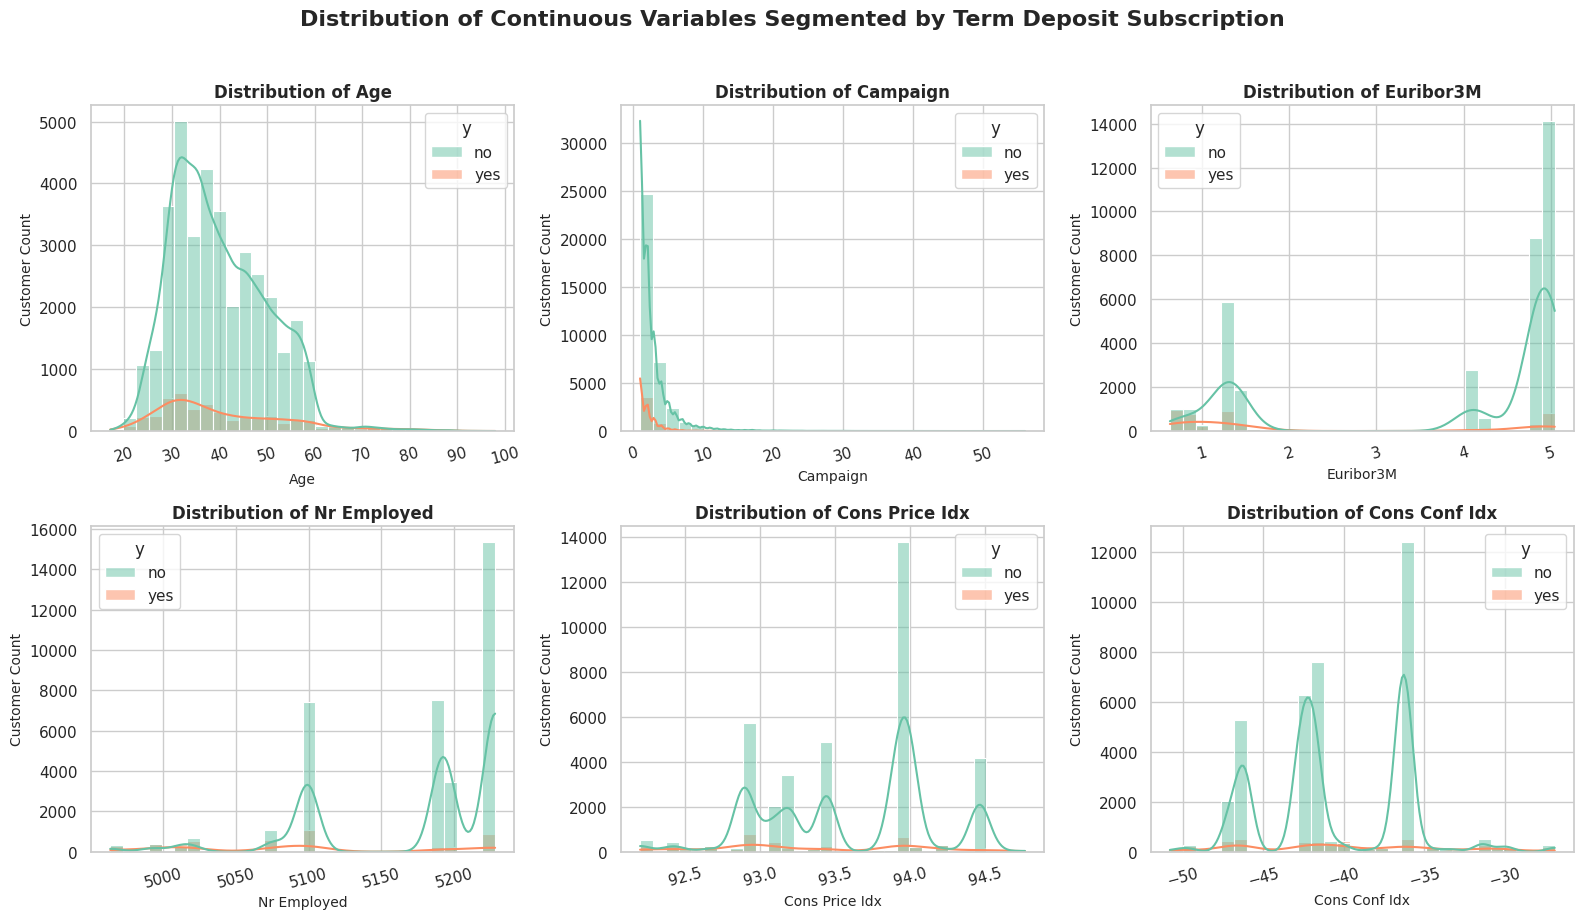

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set overall plotting aesthetics
sns.set_theme(style="whitegrid")

# Select key continuous features
continuous_cols = ['age', 'campaign', 'euribor3m', 'nr.employed', 'cons.price.idx', 'cons.conf.idx']

# Create a subplot grid (2 rows, 3 columns)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(continuous_cols):
    sns.histplot(data=df, x=col, hue='y', kde=True, ax=axes[i], palette="Set2", bins=30)
    axes[i].set_title(f'Distribution of {col.replace(".", " ").title()}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col.replace(".", " ").title(), fontsize=10)
    axes[i].set_ylabel('Customer Count', fontsize=10)
    axes[i].tick_params(axis='x', rotation=15)

plt.suptitle('Distribution of Continuous Variables Segmented by Term Deposit Subscription', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

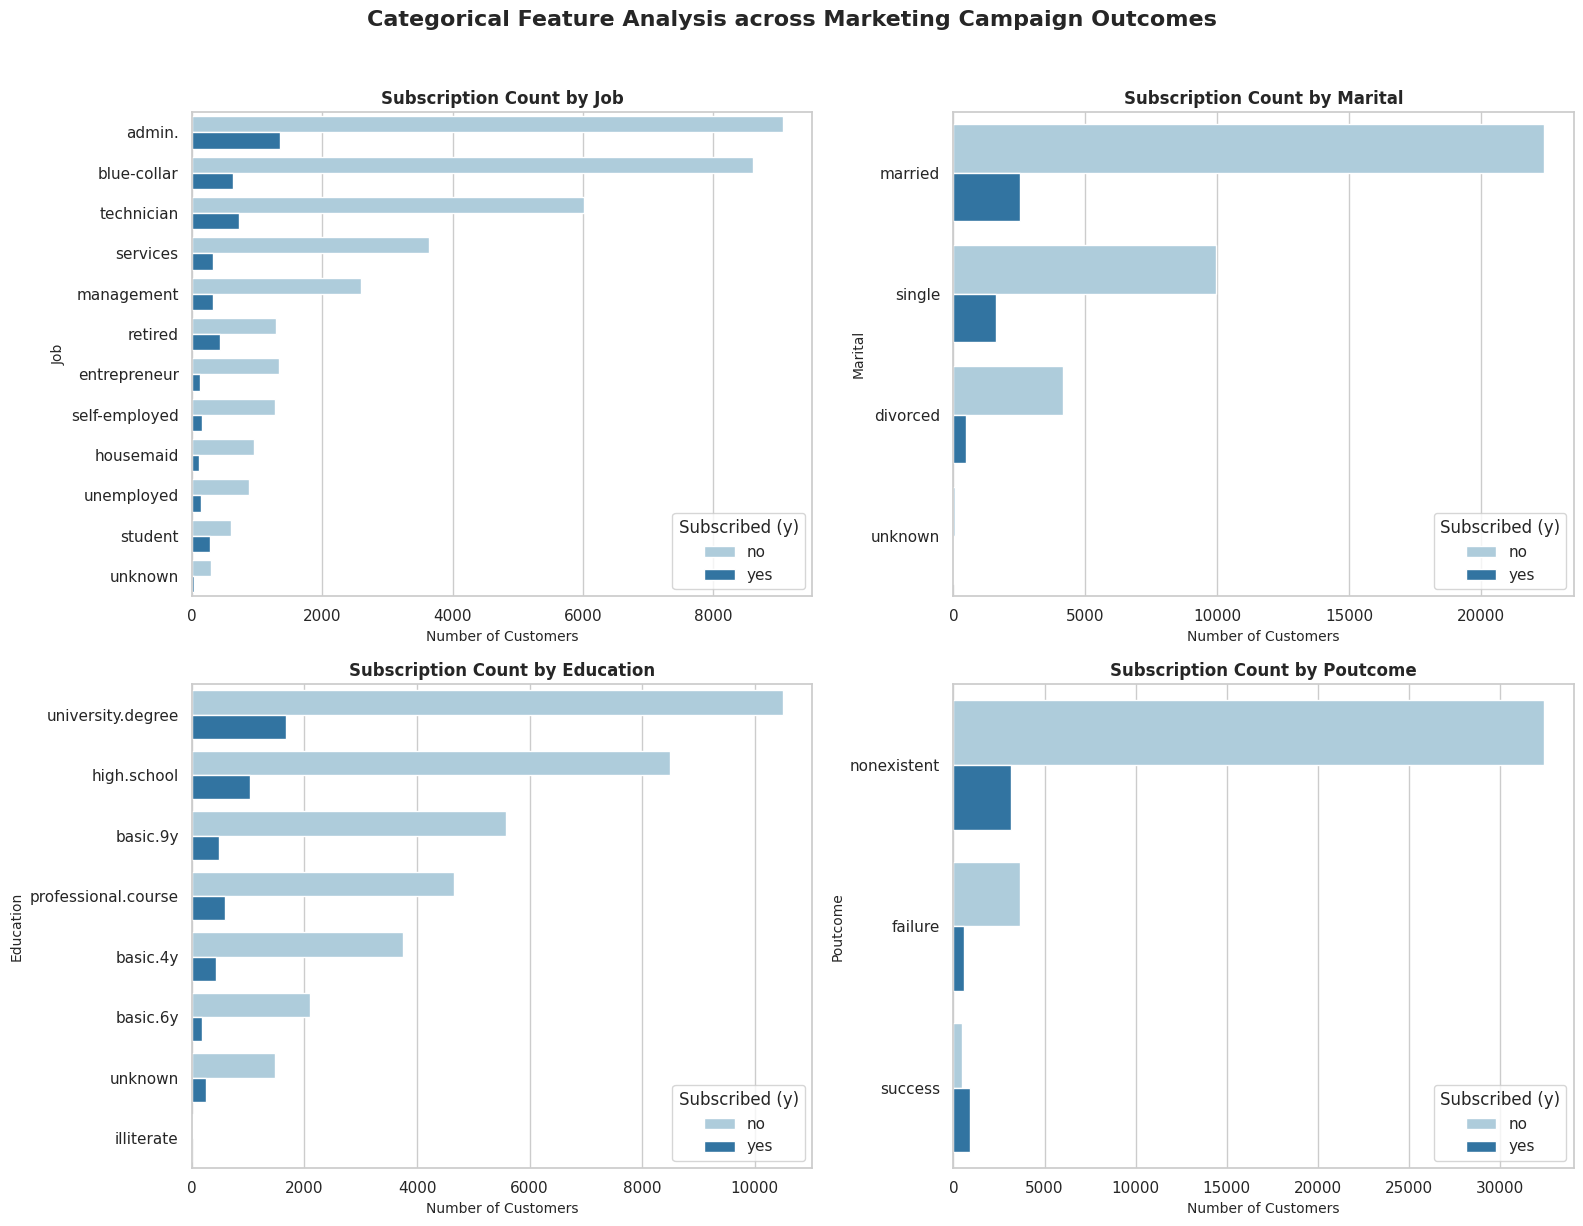

In [35]:
# Select key categorical features
categorical_cols = ['job', 'marital', 'education', 'poutcome']

# Create a subplot grid (2 rows, 2 columns)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(data=df, y=col, hue='y', ax=axes[i], palette="Paired", order=df[col].value_counts().index)
    axes[i].set_title(f'Subscription Count by {col.replace(".", " ").title()}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Number of Customers', fontsize=10)
    axes[i].set_ylabel(col.replace(".", " ").title(), fontsize=10)
    axes[i].legend(title='Subscribed (y)', loc='lower right')

plt.suptitle('Categorical Feature Analysis across Marketing Campaign Outcomes', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [36]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Separate features and target
X = df.drop(columns=['y'])
y = df['y'].apply(lambda x: 1 if str(x).strip().lower() == 'yes' else 0)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Define column transformer for scaling and one-hot encoding
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

print(f"Numerical features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Numerical features (9): ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [37]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets (70% train, 30% test) with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Target distribution in train set:\n{y_train.value_counts(normalize=True)}")

Training set shape: (28831, 19)
Testing set shape: (12357, 19)
Target distribution in train set:
y
0    0.887343
1    0.112657
Name: proportion, dtype: float64


### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [38]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Dummy classifier predicting most frequent class
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

print(f"Baseline (Dummy) Accuracy: {accuracy_score(y_test, y_pred_dummy):.4f}")
print("\nClassification Report (Dummy):\n", classification_report(y_test, y_pred_dummy, zero_division=0))

Baseline (Dummy) Accuracy: 0.8874

Classification Report (Dummy):
               precision    recall  f1-score   support

           0       0.89      1.00      0.94     10965
           1       0.00      0.00      0.00      1392

    accuracy                           0.89     12357
   macro avg       0.44      0.50      0.47     12357
weighted avg       0.79      0.89      0.83     12357



### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Build simple Logistic Regression pipeline
logreg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Train model
logreg_pipeline.fit(X_train, y_train)

# Evaluate
y_pred_logreg = logreg_pipeline.predict(X_test)
y_prob_logreg = logreg_pipeline.predict_proba(X_test)[:, 1]

print("--- Simple Logistic Regression Performance ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_logreg):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_logreg, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_logreg, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_logreg, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_logreg):.4f}")

--- Simple Logistic Regression Performance ---
Accuracy:  0.9013
Precision: 0.6972
Recall:    0.2184
F1-Score:  0.3326
ROC-AUC:   0.8034


### Problem 9: Score the Model

What is the accuracy of your model?

### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [40]:
import time
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score, accuracy_score

# Define models with default settings
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42)
}

comparison_results = []

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    start_time = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - start_time
    
    train_acc = pipe.score(X_train, y_train)
    test_acc = pipe.score(X_test, y_test)
    y_pred = pipe.predict(X_test)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    comparison_results.append({
        'Model': name,
        'Train Time (s)': round(train_time, 2),
        'Train Accuracy': round(train_acc, 4),
        'Test Accuracy': round(test_acc, 4),
        'Test F1-Score': round(f1, 4)
    })

# Create comparison DataFrame and display using standard pandas output
comparison_df = pd.DataFrame(comparison_results)
print(comparison_df)

                    Model  Train Time (s)  Train Accuracy  Test Accuracy  \
0     Logistic Regression            1.96          0.8997         0.9013   
1     K-Nearest Neighbors            0.10          0.9109         0.8953   
2           Decision Tree            0.19          0.9962         0.8394   
3  Support Vector Machine           27.64          0.9047         0.9026   

   Test F1-Score  
0         0.3326  
1         0.3879  
2         0.3287  
3         0.3665  


### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

In [41]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, roc_auc_score

# 1. Hyperparameter Tuning for Decision Tree
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

dt_param_grid = {
    'classifier__max_depth': [3, 5, 10, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("--- Best Decision Tree Parameters ---")
print(dt_grid.best_params_)
print(f"Best CV F1-Score: {dt_grid.best_score_:.4f}")

# 2. Hyperparameter Tuning for Logistic Regression
logreg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

logreg_param_grid = {
    'classifier__C': [0.01, 0.1, 1.0, 10.0],
    'classifier__solver': ['lbfgs', 'liblinear']
}

logreg_grid = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid=logreg_param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

logreg_grid.fit(X_train, y_train)

print("\n--- Best Logistic Regression Parameters ---")
print(logreg_grid.best_params_)
print(f"Best CV F1-Score: {logreg_grid.best_score_:.4f}")

# Evaluate best tuned model on test set
best_logreg = logreg_grid.best_estimator_
y_pred_best = best_logreg.predict(X_test)
y_prob_best = best_logreg.predict_proba(X_test)[:, 1]

print("\n--- Final Tuned Model Test Evaluation ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_best, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_best, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_best, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_best):.4f}")

--- Best Decision Tree Parameters ---
{'classifier__criterion': 'gini', 'classifier__max_depth': 5, 'classifier__min_samples_split': 2}
Best CV F1-Score: 0.3677

--- Best Logistic Regression Parameters ---
{'classifier__C': 10.0, 'classifier__solver': 'liblinear'}
Best CV F1-Score: 0.3392

--- Final Tuned Model Test Evaluation ---
Accuracy:  0.9013
Precision: 0.6928
Recall:    0.2220
F1-Score:  0.3362
ROC-AUC:   0.8035


##### Questions